PCA (Temel Bileşen Analizi) uygulamak teknik olarak mümkün ve veri bilimi projelerinde sıkça kullanılan güçlü bir yöntemdir. Ancak senin projendeki özel bir madde nedeniyle dikkatli olmalıyız.

Proje dosyasındaki 5. Madde (Açıklanabilir Yapay Zeka) şunu istiyor: "Modelin kararlarını yorumlayın."

PCA'nın Avantajı ve Dezavantajı (Senin Projen İçin)
Avantajı: Veri setimizde One-Hot Encoding sonrası sütun sayısı arttı (yaklaşık 50-60 sütun). PCA bunu 10-15 bileşene indirerek modelin çok daha hızlı çalışmasını ve gürültüden arınmasını sağlayabilir.

Dezavantajı (Kritik): PCA, özelliklerin ismini ve anlamını yok eder. Horsepower ve Age sütunları gider, yerine matematiksel PC1, PC2 sütunları gelir.

Sorun: Açıklanabilir Yapay Zeka (SHAP/LIME) aşamasında, "Arabanın fiyatını en çok PC1 etkiliyor" dersen, hoca "PC1 ne demek?" diye sorar ve cevabı yoktur (Çünkü PC1, beygir gücü ile vitesin matematiksel bir karışımıdır).

Önerim: PCA'yı "Analiz Aracı" Olarak Kullanalım
PCA'yı modeli eğitmek için değil, veriyi görselleştirmek ve boyutun etkisini analiz etmek için kullanalım. Böylece hem hocana "PCA yapmayı biliyorum" demiş olursun, hem de Açıklanabilir Yapay Zeka adımını baltalamamış olursun.

Aşağıdaki kod şunları yapar:

Varyans Analizi: Veri setindeki bilginin %95'ini korumak için kaç tane PCA bileşeni gerektiğini hesaplar.

2D Görselleştirme: 50 boyutlu veriyi 2 boyuta indirip araçların fiyatlarına göre nasıl kümelendiğini gösterir.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")

# 1. VERİ YÜKLEME
# ========================================================
# Önceki adımdan hazır olan işlenmiş veriyi alıyoruz
try:
    # Önceki kod çalıştıysa hafızadan al
    df_pca = df_final_processed.copy()
    print("Veri hafızadan alındı.")
except NameError:
    try:
        # Yoksa dosyadan oku
        df_pca = pd.read_csv('cleaned_used_cars_final.csv')
        print("Veri dosyadan yüklendi.")
    except:
        print("Hata: Lütfen önce 'veri_on_isleme_tamamlama.py' dosyasını çalıştırın.")

# Hedef değişkeni ayıralım (PCA sadece özelliklere uygulanır)
X = df_pca.drop('price', axis=1)
y = df_pca['price']

# Standardizasyon (PCA için ZORUNLUDUR)
# Verimiz zaten ölçekli olabilir ama garantiye almak için tekrar yapıyoruz.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Veri dosyadan yüklendi.


In [10]:
# ========================================================
# 2. PCA UYGULAMA (VARYANS ANALİZİ)
# ========================================================
# Tüm bileşenleri hesaplayıp ne kadar bilgi taşıdıklarına bakalım

pca = PCA()
pca.fit(X_scaled)

# Kümülatif Varyans (Toplam Bilgi)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# %95 Varyansı korumak için kaç bileşen lazım?
n_components95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"\n--- PCA Analiz Sonucu ---")
print(f"Orijinal Özellik Sayısı: {X.shape[1]}")
print(f"%95 Bilgiyi Korumak İçin Gereken Bileşen Sayısı: {n_components95}")
print(f"Boyut İndirgeme Oranı: %{(1 - n_components95/X.shape[1])*100:.1f}")


--- PCA Analiz Sonucu ---
Orijinal Özellik Sayısı: 73
%95 Bilgiyi Korumak İçin Gereken Bileşen Sayısı: 60
Boyut İndirgeme Oranı: %17.8


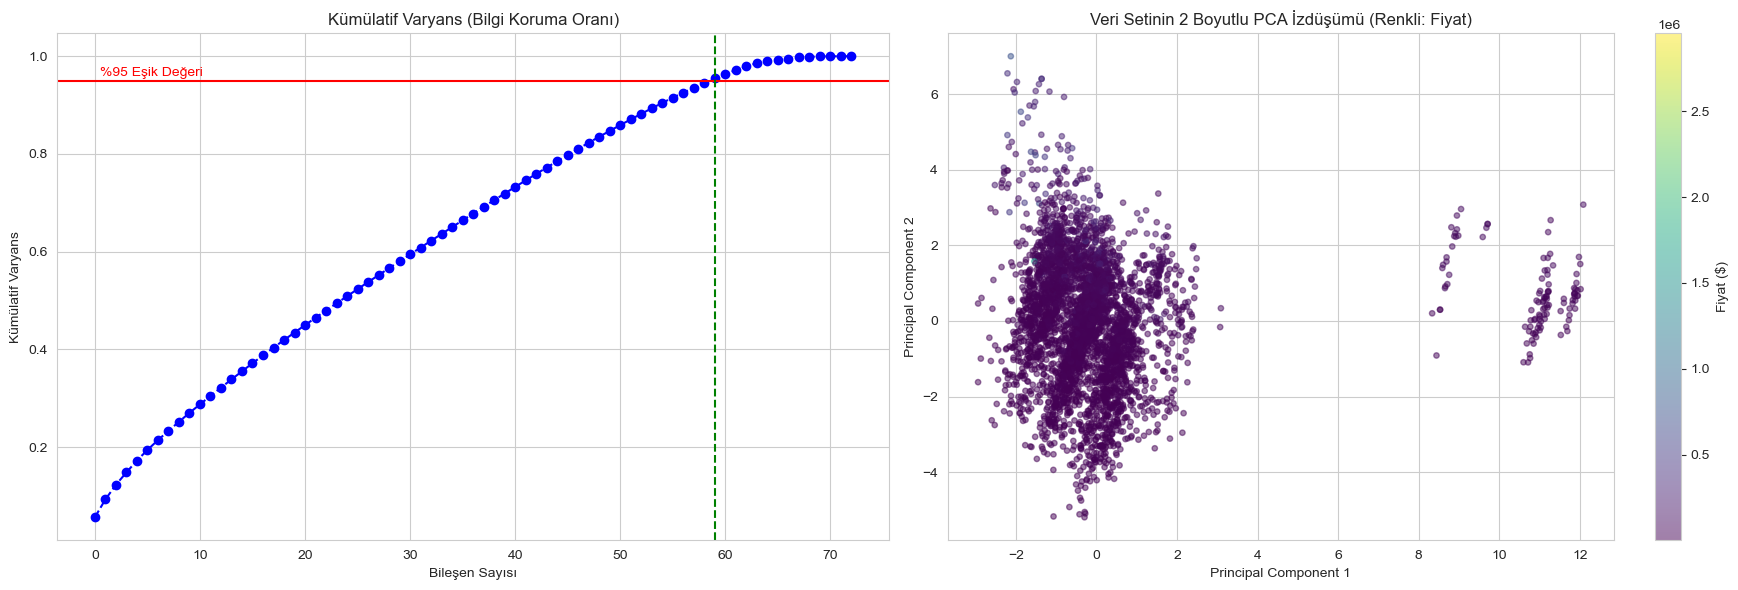

In [11]:
# ========================================================
# 3. GÖRSELLEŞTİRME (SCREE PLOT & 2D PROJECTION)
# ========================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Grafik 1: Scree Plot (Varyansın Korunumu)
axes[0].plot(cumulative_variance, marker='o', linestyle='--', color='b')
axes[0].axhline(y=0.95, color='r', linestyle='-')
axes[0].text(0.5, 0.96, '%95 Eşik Değeri', color='r')
axes[0].axvline(x=n_components95-1, color='g', linestyle='--')
axes[0].set_title('Kümülatif Varyans (Bilgi Koruma Oranı)')
axes[0].set_xlabel('Bileşen Sayısı')
axes[0].set_ylabel('Kümülatif Varyans')
axes[0].grid(True)

# Grafik 2: 2D Görselleştirme (Veriyi 2 Boyuta İndirip Bakmak)
# Veriyi 2 bileşene indiriyoruz
pca_2d = PCA(n_components=2)
components_2d = pca_2d.fit_transform(X_scaled)

# Fiyatı renklendirme için kullanalım
scatter = axes[1].scatter(components_2d[:, 0], components_2d[:, 1], 
                        c=y, cmap='viridis', alpha=0.5, s=15)
axes[1].set_title('Veri Setinin 2 Boyutlu PCA İzdüşümü (Renkli: Fiyat)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
plt.colorbar(scatter, ax=axes[1], label='Fiyat ($)')

plt.tight_layout()
plt.show()

In [12]:
# ========================================================
# 4. SONUÇ YORUMU
# ========================================================
print("\n--- YORUM ---")
if n_components95 < X.shape[1] * 0.7:
    print("PCA veriyi ciddi oranda sıkıştırabilir. Ancak 'Explainable AI' maddesi gereği,")
    print("PCA'yı model eğitiminde kullanmak yerine özellik seçimini (Random Forest) tercih ediyoruz.")
    print("Çünkü özelliklerin orijinal isimlerini (Age, HP) korumak sunum için daha önemlidir.")
else:
    print("Veri seti zaten oldukça kompakt. PCA çok büyük bir avantaj sağlamıyor.")


--- YORUM ---
Veri seti zaten oldukça kompakt. PCA çok büyük bir avantaj sağlamıyor.
